# **Eye Diseases Classification**

## Importing the Necessary Libraries

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # visualization
import seaborn as sns # visualization
import cv2
import tensorflow as tf
from tensorflow import keras
from pathlib import Path
import PIL
import os

## Load the Dataset

In [2]:
import os
folder_path = r"C:\Users\Asus\OneDrive\Desktop\Retinal disease detection\dataset\dataset"

glaucoma = Path(folder_path+'/glaucoma')
cataract = Path(folder_path+'/cataract')
normal = Path(folder_path+'/normal')
diabetic_retinopathy = Path(folder_path+'/diabetic_retinopathy')

In [3]:
from tqdm import tqdm

disease_type = [glaucoma, cataract,normal,diabetic_retinopathy]
#                  0          1      2         3
df = pd.DataFrame()
 # build the dataframe
for types in disease_type:
    for imagepath in tqdm(list(types.iterdir()), desc= str(types)):
        df = pd.concat([df, pd.DataFrame({'image': [str(imagepath)],'disease_type': [disease_type.index(types)]})], ignore_index=True)

C:\Users\Asus\OneDrive\Desktop\Retinal disease detection\dataset\dataset\glaucoma: 100%|█| 1007/1007 [00:00<00:00, 1367
C:\Users\Asus\OneDrive\Desktop\Retinal disease detection\dataset\dataset\cataract: 100%|█| 1038/1038 [00:00<00:00, 1320
C:\Users\Asus\OneDrive\Desktop\Retinal disease detection\dataset\dataset\normal: 100%|█| 1074/1074 [00:00<00:00, 1290.3
C:\Users\Asus\OneDrive\Desktop\Retinal disease detection\dataset\dataset\diabetic_retinopathy: 100%|█| 1098/1098 [00:00


In [4]:
df

,image,disease_type
0,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,0
1,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,0
2,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,0
3,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,0
4,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,0
...,...,...
4212,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,3
4213,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,3
4214,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,3
4215,C:\Users\Asus\OneDrive\Desktop\Retinal disease...,3


In [5]:
df.disease_type.value_counts()

disease_type
3    1098
2    1074
1    1038
0    1007
Name: count, dtype: int64

# Visualizing Images in dataset

In [6]:
def plot_image(n, num_samples=3):
    disease_labels = ['glaucoma', 'cataract', 'normal', 'diabetic_retinopathy']
    images = df[df['disease_type'] == n].sample(num_samples)['image']

    plt.figure(figsize=(12, 12))

    for i, path in enumerate(images, 1):
        img = (plt.imread(path) - plt.imread(path).min()) / plt.imread(path).max()
        plt.subplot(3, 3, i)
        plt.imshow(img)
        plt.axis('off')
        plt.title(disease_labels[n])

    plt.show()

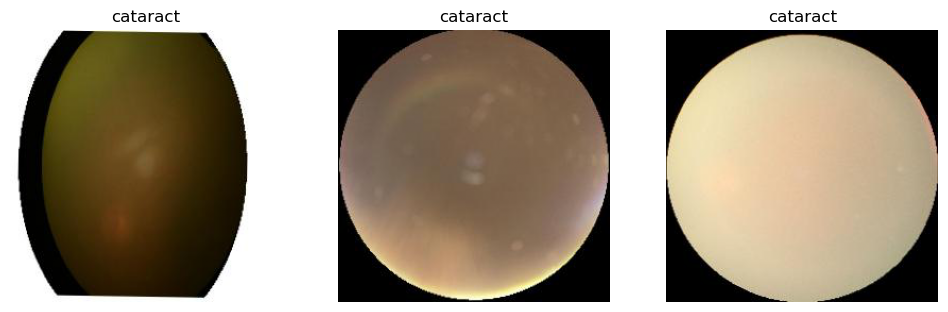

In [7]:
plot_image(1)

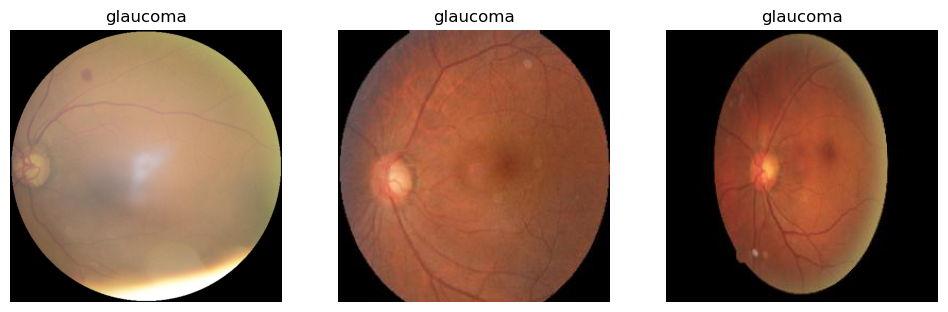

In [8]:
plot_image(0)

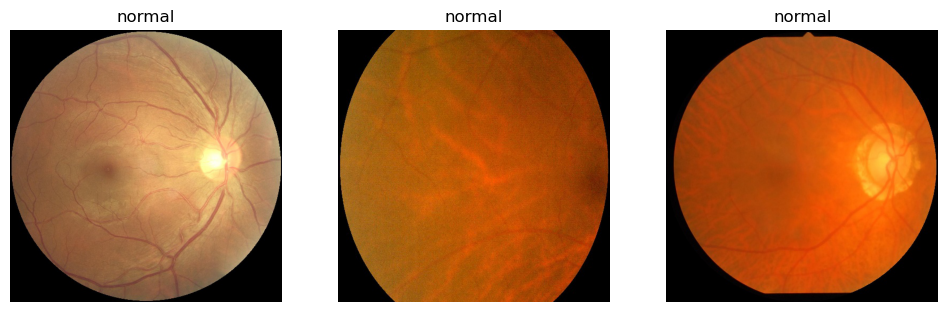

In [9]:
plot_image(2)

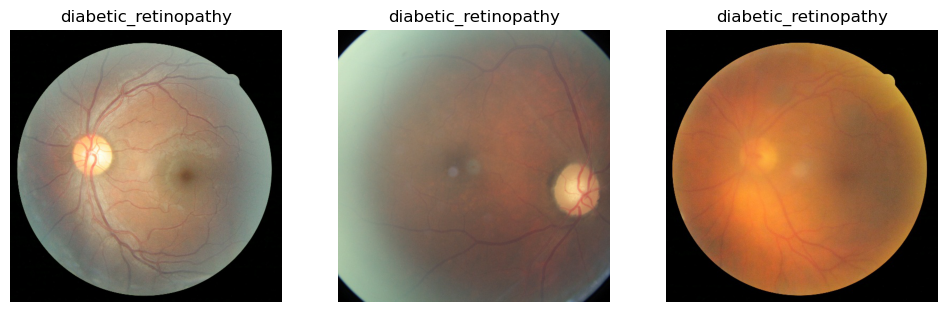

In [10]:
plot_image(3)

In [11]:
df['disease_type'] = df['disease_type'].map({0:'glaucoma',1:'cataract',2:'normal',3:'diabetic_retinopathy'})

In [12]:
df.disease_type.value_counts()

disease_type
diabetic_retinopathy    1098
normal                  1074
cataract                1038
glaucoma                1007
Name: count, dtype: int64

In [13]:
# shuffling the rows of a DataFrame df
df1=df.sample(frac=1).reset_index(drop=True)

C:\Users\Asus\AppData\Local\Temp\ipykernel_16212\1364475135.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='disease_type', data=df1, palette=custom_palette)


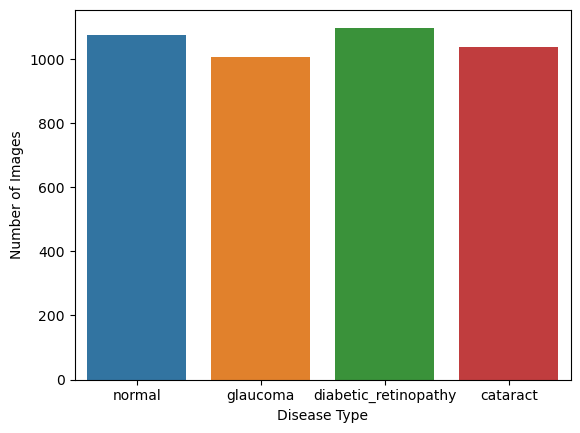

In [14]:
custom_palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

# Assuming 'df1' contains your DataFrame with 'disease_type' column
sns.countplot(x='disease_type', data=df1, palette=custom_palette)
plt.xlabel('Disease Type')
plt.ylabel('Number of Images')

# Save the plot as an image
plt.savefig('countplot.png')

plt.show()

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,Dense,BatchNormalization,MaxPooling2D,Conv2DTranspose,Activation
, Input,concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dropout, GlobalAveragePooling2D, Add, DepthwiseConv2D,Flatten
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, BatchNormalization, Dropout, RandomContrast, RandomRotation, RandomZoom, RandomFlip
from tensorflow.keras.utils import to_categorical, plot_model, image_dataset_from_directory

# Data Training& Testing

In [16]:
from sklearn.model_selection import train_test_split

# Split your data into features (X) and labels (y)
X = df1['image']  # 'image' contains image data
y = df1['disease_type']  # 'disease_type' contains labels

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [17]:
datagen = ImageDataGenerator(preprocessing_function=preprocess_input,validation_split=0.2)


In [18]:
# Data generators for training
train_data = datagen.flow_from_dataframe(dataframe=df1,
                                          x_col ='image',
                                          y_col = 'disease_type',
                                          target_size=(224,224),
                                          class_mode = 'categorical',
                                          batch_size = 32,
                                          shuffle = True,
                                          subset = 'training')

Found 3374 validated image filenames belonging to 4 classes.


In [19]:
# Data generators for validation
valid_data=datagen.flow_from_dataframe(dataframe=df1,
                                      x_col='image',
                                      y_col = 'disease_type',
                                      target_size = (224,224),
                                      class_mode= 'categorical',
                                      batch_size = 32,
                                      shuffle = False,
                                      subset= 'validation')

Found 843 validated image filenames belonging to 4 classes.


In [20]:
if (train_data.class_indices == valid_data.class_indices):

    # Print that the class indices are consistent
    print("Class indices are consistent")

    # Save class indices as metadata in metadata.js
    class_indices = train_data.class_indices
    print(class_indices)
    js_code = f"const classIndices = {class_indices};\nexport default classIndices;"
    with open('metadata.js', 'w') as f:
        f.write(js_code)
else:
    print("Class indices are not consistent")# Check if class indices are consistent


Class indices are consistent
{'cataract': 0, 'diabetic_retinopathy': 1, 'glaucoma': 2, 'normal': 3}


# Building The Model

In [21]:
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, BatchNormalization, Dropout, RandomContrast, RandomRotation, RandomZoom, RandomFlip
from keras.models import Sequential


In [22]:
labels=[key for key in train_data.class_indices]
num_classes = len(disease_type)

In [23]:
from tensorflow.keras.applications import VGG19
from tensorflow.keras.layers import Flatten, Dense, BatchNormalization, Dropout
from tensorflow.keras.models import Model

image_size = 224

# Load pre-trained VGG19 without top layers
vgg = VGG19(weights='imagenet', include_top=False, input_shape=(image_size, image_size, 3))

# Freeze convolutional base
for layer in vgg.layers:
    layer.trainable = False

# Add custom layers on top
x = Flatten()(vgg.output)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
output = Dense(4, activation='softmax')(x)

# Create the full model
model = Model(inputs=vgg.input, outputs=output)

# Compile
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv4 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv4 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv4 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 26,449,220 (100.90 MB)

 Trainable params: 6,424,324 (24.51 MB)

 Non-trainable params: 20,024,896 (76.39 MB)

In [24]:
pip install pydot graphviz


Note: you may need to restart the kernel to use updated packages.


In [25]:
import graphviz
import pydot

print("Graphviz and pydot are installed correctly!")


Graphviz and pydot are installed correctly!


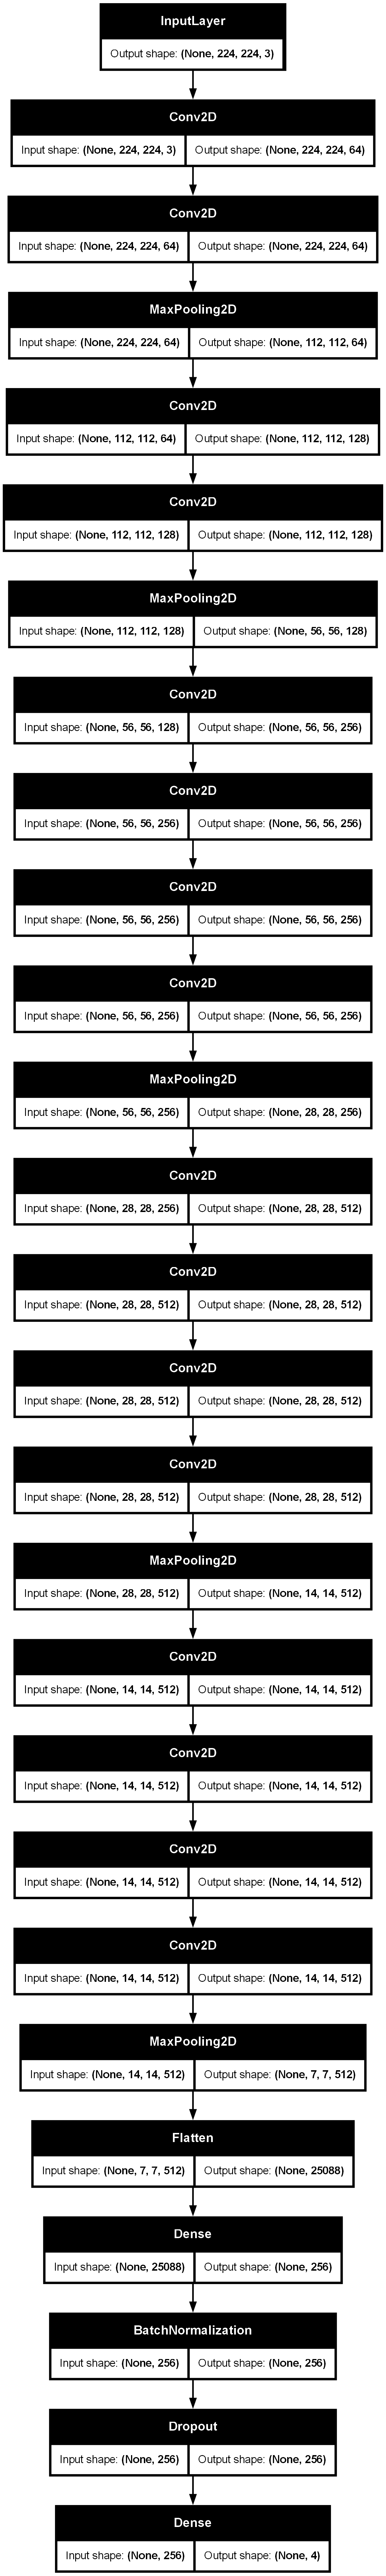

In [26]:
tf.keras.utils.plot_model(model,
                          to_file="model.png",
                          show_shapes=True,
                          expand_nested=True)

In [31]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint = ModelCheckpoint(
    "vgg19.h5",
    monitor="val_accuracy",   # monitors validation accuracy
    verbose=1,
    save_best_only=True,
    save_weights_only=False,
    save_freq='epoch'
)

earlystop = EarlyStopping(
    monitor="val_accuracy",
    patience=5,   # stop if val_accuracy doesn’t improve for 5 epochs
    verbose=1,
    restore_best_weights=True
)


In [32]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    verbose=1,
    min_lr=1e-6
)

his = model.fit(
    train_data,
    epochs=32,
    validation_data=valid_data,
    verbose=1,
    callbacks=[checkpoint, earlystop, reduce_lr]
)


Epoch 1/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8282 - loss: 0.5176   

C:\Users\Asus\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 1: val_accuracy improved from None to 0.86714, saving model to vgg19.h5


106/106 ━━━━━━━━━━━━━━━━━━━━ 825s 8s/step - accuracy: 0.8506 - loss: 0.4248 - val_accuracy: 0.8671 - val_loss: 0.3613 - learning_rate: 0.0010
Epoch 2/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9211 - loss: 0.2125  
Epoch 2: val_accuracy improved from 0.86714 to 0.87426, saving model to vgg19.h5


106/106 ━━━━━━━━━━━━━━━━━━━━ 627s 6s/step - accuracy: 0.9206 - loss: 0.2173 - val_accuracy: 0.8743 - val_loss: 0.3755 - learning_rate: 0.0010
Epoch 3/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9557 - loss: 0.1306  
Epoch 3: val_accuracy did not improve from 0.87426
106/106 ━━━━━━━━━━━━━━━━━━━━ 621s 6s/step - accuracy: 0.9511 - loss: 0.1481 - val_accuracy: 0.8612 - val_loss: 0.3892 - learning_rate: 0.0010
Epoch 4/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9624 - loss: 0.1055  
Epoch 4: val_accuracy did not improve from 0.87426

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
106/106 ━━━━━━━━━━━━━━━━━━━━ 615s 6s/step - accuracy: 0.9647 - loss: 0.1032 - val_accuracy: 0.8588 - val_loss: 0.3987 - learning_rate: 0.0010
Epoch 5/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9840 - loss: 0.0607  
Epoch 5: val_accuracy improved from 0.87426 to 0.88612, saving model to vgg19.h5


106/106 ━━━━━━━━━━━━━━━━━━━━ 606s 6s/step - accuracy: 0.9867 - loss: 0.0530 - val_accuracy: 0.8861 - val_loss: 0.3303 - learning_rate: 2.0000e-04
Epoch 6/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9901 - loss: 0.0364  
Epoch 6: val_accuracy improved from 0.88612 to 0.89087, saving model to vgg19.h5


106/106 ━━━━━━━━━━━━━━━━━━━━ 606s 6s/step - accuracy: 0.9905 - loss: 0.0363 - val_accuracy: 0.8909 - val_loss: 0.3440 - learning_rate: 2.0000e-04
Epoch 7/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9953 - loss: 0.0266  
Epoch 7: val_accuracy did not improve from 0.89087
106/106 ━━━━━━━━━━━━━━━━━━━━ 624s 6s/step - accuracy: 0.9944 - loss: 0.0273 - val_accuracy: 0.8885 - val_loss: 0.3473 - learning_rate: 2.0000e-04
Epoch 8/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9958 - loss: 0.0215  
Epoch 8: val_accuracy did not improve from 0.89087

Epoch 8: ReduceLROnPlateau reducing learning rate to 4.0000001899898055e-05.
106/106 ━━━━━━━━━━━━━━━━━━━━ 628s 6s/step - accuracy: 0.9961 - loss: 0.0218 - val_accuracy: 0.8909 - val_loss: 0.3641 - learning_rate: 2.0000e-04
Epoch 9/32
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9964 - loss: 0.0184  
Epoch 9: val_accuracy did not improve from 0.89087
106/106 ━━━━━━━━━━━━━━━━━━━━ 638s 6s/step - accuracy: 0.9970 - loss: 0

In [33]:

loss, accuracy = model.evaluate(valid_data)
print("Loss:", loss)
print("Accuracy:", accuracy)

27/27 ━━━━━━━━━━━━━━━━━━━━ 93s 3s/step - accuracy: 0.8909 - loss: 0.3440 
Loss: 0.3440447151660919
Accuracy: 0.8908659815788269


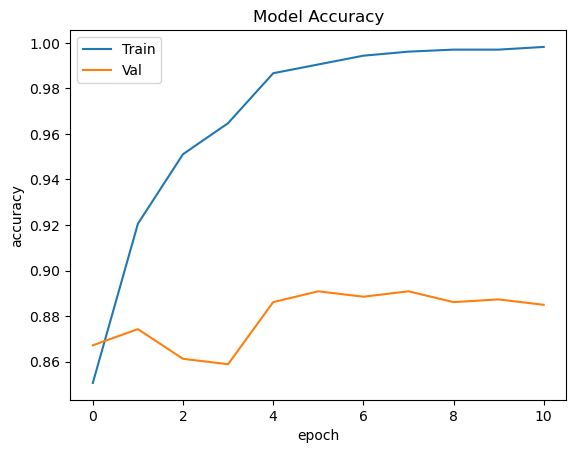

In [34]:
plt.plot(his.history['accuracy'])
plt.plot(his.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['Train', 'Val'])
plt.show()

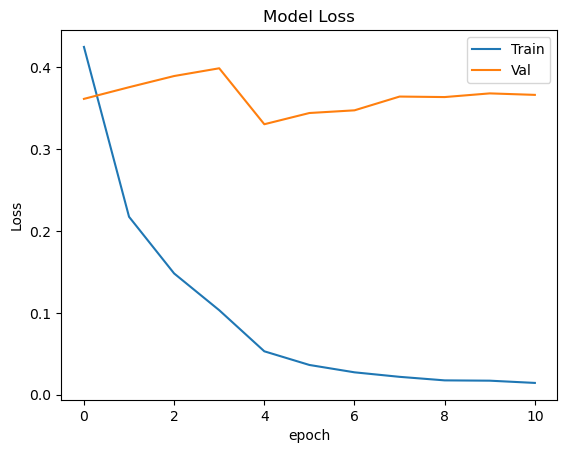

In [35]:
plt.plot(his.history['loss'])
plt.plot(his.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('epoch')
plt.legend(['Train', 'Val'])
plt.show()

In [36]:
def tr_plot(tr_data, start_epoch):
    #Plot the loss and accuracy curve
    tacc=tr_data.history['accuracy']
    tloss=tr_data.history['loss']
    vacc=tr_data.history['val_accuracy']
    vloss=tr_data.history['val_loss']
    Epoch_count=len(tacc)+ start_epoch
    Epochs=[]
    for i in range (start_epoch ,Epoch_count):
        Epochs.append(i+1)
    index_loss=np.argmin(vloss)#  this is the epoch with the lowest validation loss
    val_lowest=vloss[index_loss]
    index_acc=np.argmax(vacc)
    acc_highest=vacc[index_acc]
    plt.style.use('fivethirtyeight')
    sc_label='best epoch= '+ str(index_loss+1 +start_epoch)
    vc_label='best epoch= '+ str(index_acc + 1+ start_epoch)
    fig,axes=plt.subplots(nrows=1, ncols=2, figsize=(20,8))
    axes[0].plot(Epochs,tloss, 'r', label='Training loss')
    axes[0].plot(Epochs,vloss,'g',label='Validation loss' )
    axes[0].scatter(index_loss+1 +start_epoch,val_lowest, s=150, c= 'blue', label=sc_label)
    axes[0].set_title('Training and Validation Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[1].plot (Epochs,tacc,'r',label= 'Training Accuracy')
    axes[1].plot (Epochs,vacc,'g',label= 'Validation Accuracy')
    axes[1].scatter(index_acc+1 +start_epoch,acc_highest, s=150, c= 'blue', label=vc_label)
    axes[1].set_title('Training and Validation Accuracy')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    plt.tight_layout

    plt.show()

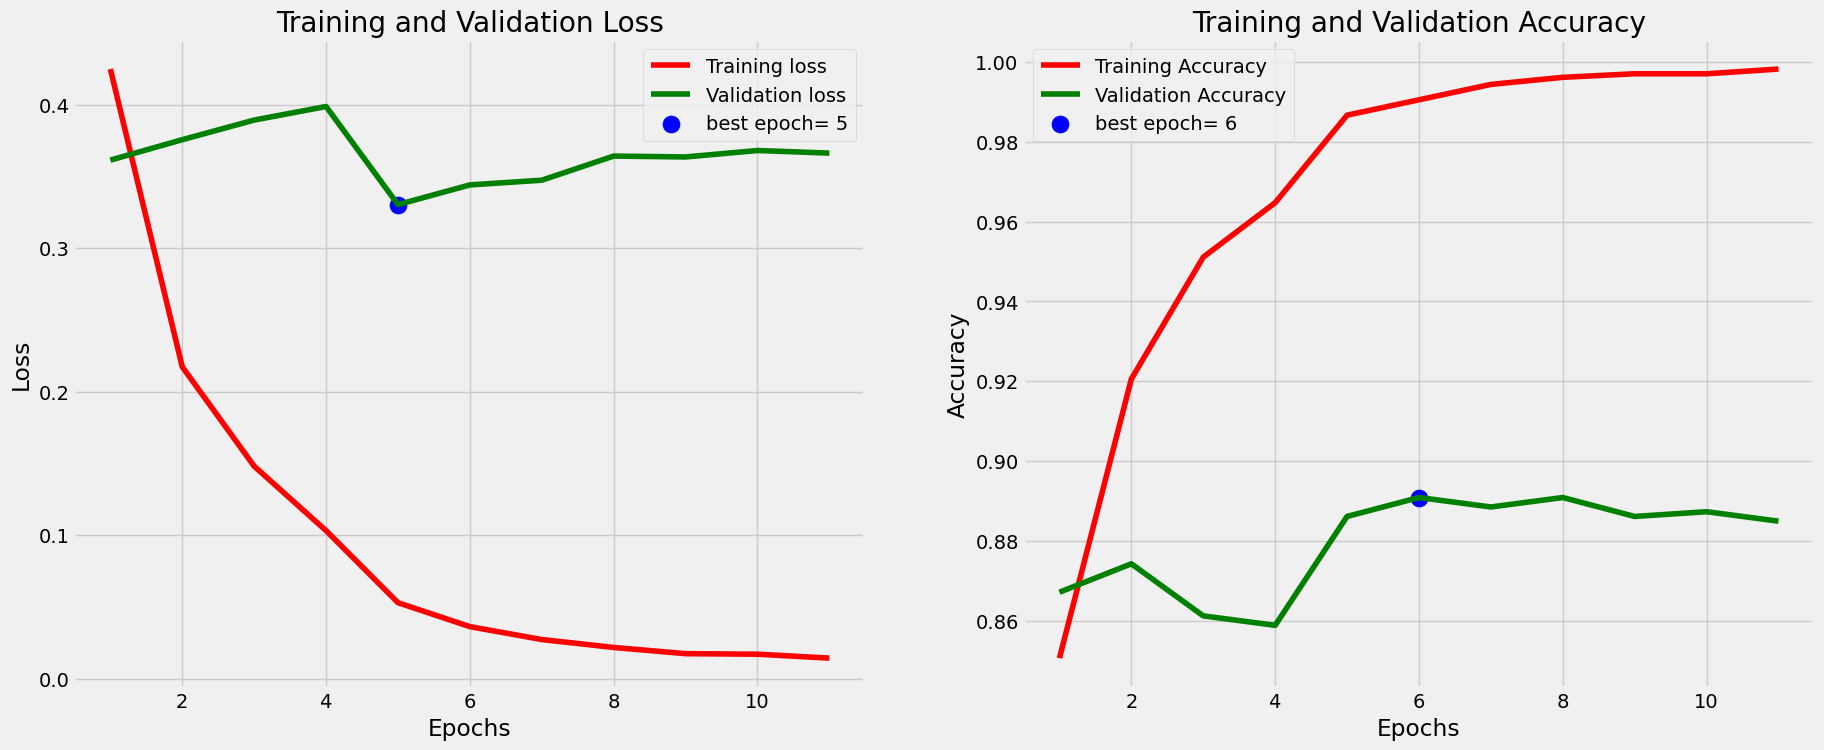

<Figure size 640x480 with 0 Axes>

In [37]:
# plot the history
tr_plot(his,0)
plt.savefig('history.png')


# Model Evaluation

In [38]:
y_test = valid_data.classes
y_pred = model.predict(valid_data)
y_pred = np.argmax(y_pred,axis=1)

27/27 ━━━━━━━━━━━━━━━━━━━━ 129s 5s/step


In [40]:
!pip install mlxtend


   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.4 MB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.3 MB/s eta 0:00:00


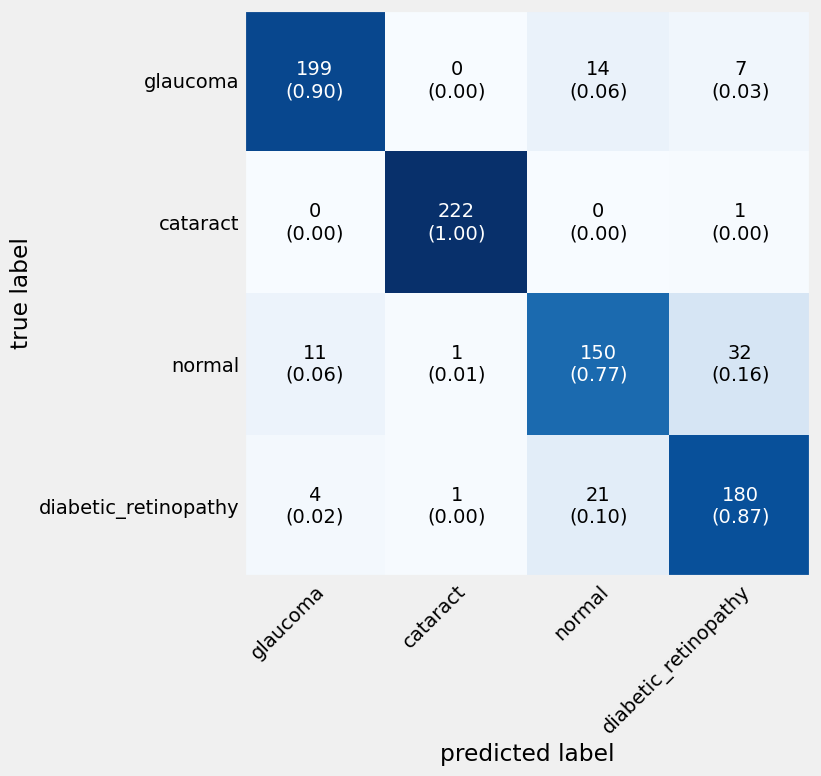

In [41]:
from mlxtend.plotting import plot_confusion_matrix
cm = confusion_matrix(y_test,y_pred)
plot_confusion_matrix(conf_mat = cm,figsize=(8,7),class_names = ["glaucoma", "cataract", "normal", "diabetic_retinopathy"],
                      show_normed = True);
plt.savefig("Predected & True Label")

In [42]:
print(classification_report(y_test,y_pred,target_names = labels))

                      precision    recall  f1-score   support

            cataract       0.93      0.90      0.92       220
diabetic_retinopathy       0.99      1.00      0.99       223
            glaucoma       0.81      0.77      0.79       194
              normal       0.82      0.87      0.85       206

            accuracy                           0.89       843
           macro avg       0.89      0.89      0.89       843
        weighted avg       0.89      0.89      0.89       843



1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


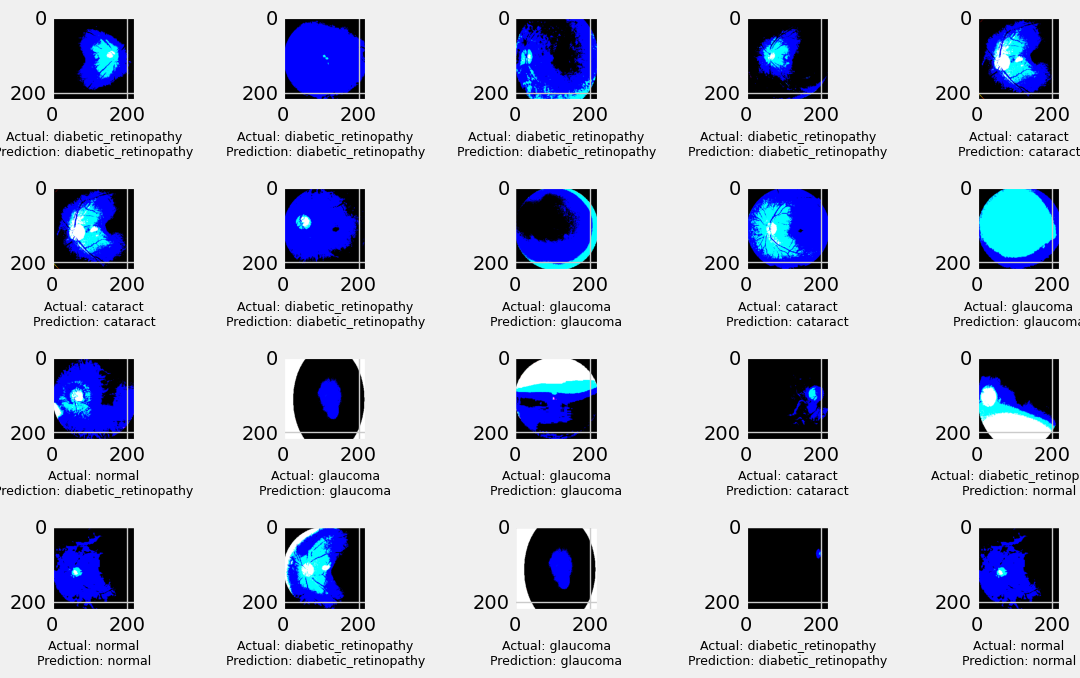

In [43]:
import random
import matplotlib.pyplot as plt

# Define the class labels
class_labels = ["glaucoma", "cataract", "normal", "diabetic_retinopathy"]

# Get a batch of data from the valid_data generator
images, labels = next(valid_data)

# Replace these variables with your actual data
y_pred = model.predict(images)  # Assuming you have a trained model

plt.figure(figsize=(12, 7))

for i in range(20):
    sample_index = random.randint(0, images.shape[0] - 1)
    image = images[sample_index]
    category_index = labels[sample_index].argmax()
    pred_category_index = y_pred[sample_index].argmax()

    label = class_labels[category_index]
    pred_label = class_labels[pred_category_index]

    plt.subplot(4, 5, i + 1)
    plt.imshow(image)

    # Change the font size for labels
    plt.xlabel("Actual: {}\nPrediction: {}".format(label, pred_label), fontsize=9)  # Change the fontsize as needed

plt.tight_layout()

# Save the plot as an image
plt.savefig('Model Eval.png')

plt.show()

In [44]:
model.save("Retinal Disease Classification")

ValueError: Invalid filepath extension for saving. Please add either a `.keras` extension for the native Keras format (recommended) or a `.h5` extension. Use `model.export(filepath)` if you want to export a SavedModel for use with TFLite/TFServing/etc. Received: filepath=Retinal Disease Classification.